# Multi-dataset LSTM: baseline, tuning, evaluation and predictions

## What this notebook does
1. Loads a configurable list of **separate cleaned datasets** and pools their binary-labelled rows for training one shared LSTM.
2. Evaluates a baseline with five-fold grouped cross-validation, then fits it on **all supplied labelled rows** and evaluates that model on each input dataset and the pooled rows.
3. Tunes hyperparameters, fits the chosen tuned configuration on all labelled rows, and repeats evaluation.
4. Compares baseline versus tuned using **pooled out-of-fold PR AUC first and ROC AUC second**, selects a winner, and saves **one final prediction CSV per dataset**.

Dataset0 and dataset1 use their binary `label`. Dataset2 also uses **`label`**, which the cleaning code creates from fractions after an explicit conversion rule. `modification_fraction`, `label_raw` and `label_value` never enter the model. No fractional conversion happens here.

**Two distinct evaluations:** “training_data” evaluates the full-data model on its own training rows; this is the all-data workflow requested, not an independent test. “oof_validation” uses predictions for rows excluded from each fold's training. Tuning/selection use these same folds, so selected-model CV scores have selection bias. No permanent test split is made. Independent held-out data or nested CV is still needed for final generalization claims.

**Source contract:** `m6a_clean_multiple_datasets.ipynb` exports `clean_labeled_sites.csv.gz` and `clean_signal_sites.csv.gz` separately for each dataset. The supplied copy still enables only dataset0. Enable all three cleaning entries and explicitly convert dataset2 fractions before running this notebook; `fraction_rule='preserve'` produces no binary training rows. Keep the conversion's biological justification in your report.

**Validation:** the supplied real cleaned tables are not available here. The notebook is tested with small synthetic tables for implementation checks; no real-data performance is claimed.

## 1. Install packages and choose your kernel
On Ronin, use a Python environment created on Ronin; a Windows `.venv` cannot be reused there. Select it in VS Code's notebook kernel picker. Uncomment the installation line if needed, then restart the kernel. PyTorch automatically uses CUDA if available; CPU also works.

In [1]:
# Run once if necessary, then restart the kernel.
# %pip install torch numpy pandas scikit-learn matplotlib joblib ipykernel
from pathlib import Path
from datetime import datetime, timezone
import json, random, platform, sys, importlib.metadata, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, ParameterSampler
from sklearn.metrics import (average_precision_score, roc_auc_score,
    precision_recall_curve, roc_curve, auc, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay)
from IPython.display import display
plt.rcParams.update({'figure.figsize': (8, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| PyTorch:', torch.__version__)

Device: cpu | PyTorch: 2.14.1+cpu


## 2. Edit input paths and runtime settings
Set `PROJECT_ROOT` to your `Team_Project` folder. Replace each `EDIT_RUN_FOLDER` with the timestamp folder printed by the cleaner. To add another dataset/file, add an entry with a unique `dataset_id` and a labelled-table path. Paths may be absolute or relative to `PROJECT_ROOT`.

- `train_csv`: binary-labelled cleaned table used for training and evaluation.
- `predict_csv`: signal table to predict, including unlabelled QC-passing sites. Set `None` to predict only rows in `train_csv`.
- `label_column`: `label` for **all three** current datasets.
- `RUN_TUNING`: `False` for a baseline-only first run; `True` executes the full comparison.
- `N_TRIALS`: random search trials, default 8. A full default run performs 47 fits (5 baseline folds + 1 baseline full fit + 40 tuning folds + 1 tuned full fit). It can take substantial compute time.
- `BASELINE['epochs']`: baseline training passes, default 15. Tuning epoch choices are separate.
- `batch_size`: lower it if memory is tight. `CPU_THREADS` limits CPU contention.
- `THRESHOLD=0.5`: used only for precision/recall/F1/confusion counts; **ROC AUC and PR AUC use scores across thresholds**, not thresholded predictions.

Training uses all rows with equal per-row contribution: larger datasets contribute more. `balanced` loss weighting balances the pooled classes, not datasets. The original cleaning files stay separate and unchanged. Outputs are saved outside the Git repository.

In [2]:
PROJECT_ROOT = Path(r'D:/NUS/AY2627_Year_4/AY2627_Y4_Sem1/DSA4262_genomics/Assignments/Team_Project')
DATASETS = [
    dict(dataset_id='dataset0',
         train_csv='outputs/data_cleaning/dataset0/20261006T143139_734059Z/clean_labeled_sites.csv.gz',
         predict_csv=None,
         label_column='label'),
    dict(dataset_id='dataset1',
         train_csv='outputs/data_cleaning/dataset1/20261006T144017_412380Z/clean_labeled_sites.csv.gz',
         predict_csv=None,
         label_column='label'),
    dict(dataset_id='dataset2',
         train_csv='outputs/data_cleaning/dataset2/20261006T144639_349494Z/clean_labeled_sites.csv.gz',
         predict_csv=None,
         label_column='label'),
]
OUTPUT_ROOT = PROJECT_ROOT / 'outputs' / 'lstm_output'
SEED = 42
N_FOLDS = 5
RUN_TUNING = True  # False: baseline only; True: baseline + tuning + comparison
N_TRIALS = 8
CPU_THREADS = 2
ALLOW_PREFIX_DATA = False
THRESHOLD = 0.5
BASELINE = dict(hidden_size=32, dropout=0.0, lr=0.001,
                batch_size=256, epochs=15, class_weight='none')
SEARCH_SPACE = dict(hidden_size=[16, 32, 64], dropout=[0.0, 0.2, 0.4],
                    lr=[0.0003, 0.001, 0.003], batch_size=[128, 256],
                    epochs=[10, 20, 30], class_weight=['none', 'balanced'])
KEY = ['transcript_id', 'transcript_position']
POSITIONS = ['minus1', 'center', 'plus1']
MEASURES = ['dwell', 'signal_sd', 'signal_mean']
STATS = ['mean', 'std', 'median', 'q25', 'q75']
FEATURE_COLUMNS = [f'{pos}_{measure}_{stat}'
                   for pos in POSITIONS for stat in STATS for measure in MEASURES]
INPUT_SIZE = 15
# The model uses these 45 signal summaries only, not the entire CSV.
# Coverage and sequence/motif can be investigated in a later model variant.
torch.set_num_threads(CPU_THREADS)
if not DATASETS or (RUN_TUNING and N_TRIALS < 1):
    raise ValueError('Provide datasets and at least one tuning trial when tuning is enabled.')
if any((p / '.git').exists() for p in (OUTPUT_ROOT.resolve(), *OUTPUT_ROOT.resolve().parents)):
    raise ValueError('OUTPUT_ROOT must be outside your Git repository.')
RUN_DIR = OUTPUT_ROOT / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN_DIR.mkdir(parents=True, exist_ok=False)
print('Output folder:', RUN_DIR)

Output folder: D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\outputs\lstm_output\20261007T031749_054814Z


## 3. Validate each file and pool the binary-labelled rows
The 45 summaries are reordered explicitly into **3 positions × 15 measurements per position**. Each sample is one site. This LSTM follows the ordered positions minus1 → centre → plus1; it does not treat unordered reads as a sequence. Read-level dependencies were lost during cleaning.

There is no automatic deduplication across datasets: repeated sites may be genuine separate measurements. We retain dataset provenance and audit shared keys/discordant labels. Shared transcripts and known genes are kept together during validation. Different datasets may have different target definitions, especially converted fractions; pooled performance must be interpreted alongside the per-dataset results.

Empty binary files, missing/non-binary labels, nonfinite predictors, duplicate keys within a file, mismatched dataset IDs and known prefix-only cleaning runs stop with a clear error. Single-class datasets remain in training and prediction, but their individual ROC/PR AUC is marked undefined.

In [3]:
import re

def resolve_path(value):
    p = Path(value).expanduser()
    return (p if p.is_absolute() else PROJECT_ROOT / p).resolve()

def validate_features(frame, require_labels=False):
    required = KEY + FEATURE_COLUMNS + (['label'] if require_labels else [])
    missing = sorted(set(required) - set(frame.columns))
    if missing:
        raise ValueError(f'Missing columns: {missing}')
    if frame.empty or frame.duplicated(KEY).any() or frame[KEY].isna().any().any():
        raise ValueError('Empty table, missing site keys, or duplicate site keys.')
    if frame.transcript_id.astype(str).str.strip().eq('').any():
        raise ValueError('Empty transcript IDs.')
    pos = pd.to_numeric(frame.transcript_position, errors='raise')
    if not np.isfinite(pos).all() or (pos < 0).any() or (pos % 1 != 0).any():
        raise ValueError('Positions must be nonnegative integers.')
    frame['transcript_position'] = pos.astype('int64')
    values = frame[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
    if not np.isfinite(values).all():
        raise ValueError('Nonfinite model features: review cleaning; do not silently impute.')
    if require_labels and (frame.label.isna().any() or not frame.label.isin([0, 1]).all()):
        raise ValueError('Expected binary, nonmissing labels.')
    return values


frames, manifests, resolved_inputs = [], {}, []
ids = [c['dataset_id'] for c in DATASETS]
if len(set(ids)) != len(ids) or any(not re.fullmatch(r'[A-Za-z0-9_-]+', s) for s in ids):
    raise ValueError('Use unique dataset IDs containing letters, digits, _ or -.')
if 'COMBINED' in ids:
    raise ValueError('COMBINED is reserved for pooled evaluation.')
for config in DATASETS:
    name = config['dataset_id']
    path = resolve_path(config['train_csv'])
    if not path.is_file(): raise FileNotFoundError(f'{name}: edit train_csv: {path}')
    pred_path = resolve_path(config['predict_csv']) if config.get('predict_csv') else path
    if not pred_path.is_file(): raise FileNotFoundError(f'{name}: edit predict_csv: {pred_path}')
    frame = pd.read_csv(path, dtype={'transcript_id': str, 'gene_id': str})
    label_col = config.get('label_column', 'label')
    if label_col not in frame: raise ValueError(f'{name}: missing binary label column {label_col}')
    if frame.empty: raise ValueError(f'{name}: empty binary table. Check cleaning QC and fraction_rule; preserve creates no binary labels.')
    if 'dataset_id' in frame and not frame.dataset_id.eq(name).all():
        raise ValueError(f'{name}: dataset_id inside file does not match this entry.')
    frame['dataset_id'] = name
    frame['label'] = pd.to_numeric(frame[label_col], errors='raise')
    validate_features(frame, require_labels=True)
    if 'gene_id' not in frame: frame['gene_id'] = pd.NA
    frame['gene_id'] = frame.gene_id.replace(r'^\s*$', pd.NA, regex=True)
    manifest_path = path.parent / 'run_manifest.json'
    manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else None
    if manifest is not None:
        if manifest.get('dataset_id') not in (None, name):
            raise ValueError(f'{name}: manifest dataset ID mismatch.')
        if manifest.get('max_lines') is not None and not ALLOW_PREFIX_DATA:
            raise ValueError(f'{name}: prefix cleaning detected; rerun cleaner with MAX_LINES=None.')
        if manifest.get('config', {}).get('label_type') == 'fraction':
            rule = manifest.get('fraction_rule_applied')
            threshold = manifest.get('fraction_threshold_applied')
            print(f'{name}: binary targets from fractions, rule={rule}, threshold={threshold}')
            if rule not in ('nonzero', 'threshold'):
                raise ValueError(f'{name}: cleaning manifest does not establish binary conversion.')
    else:
        print(f'{name}: manifest absent; verify full-data cleaning and label provenance yourself.')
    manifests[name] = manifest
    frames.append(frame)
    resolved_inputs.append(dict(dataset_id=name, train_csv=str(path), predict_csv=str(pred_path), label_column=label_col))

# Concatenate only in memory; raw/cleaned source files remain independent.
df = pd.concat(frames, ignore_index=True)
X = df[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
y = df.label.to_numpy(dtype=np.int64)
if len(np.unique(y)) != 2: raise ValueError('Pooled training data need both binary classes.')
summary = df.groupby('dataset_id', sort=False).agg(sites=('label','size'), positives=('label','sum'), positive_fraction=('label','mean'))
display(summary)
summary.to_csv(RUN_DIR / 'input_summary.csv')
print('Pooled feature tensor:', (len(y), 3, INPUT_SIZE))
shared = df.groupby(KEY).agg(datasets=('dataset_id','nunique'), label_values=('label','nunique'))
shared = shared.loc[shared.datasets > 1]
shared.to_csv(RUN_DIR / 'shared_site_audit.csv')
print('Shared transcript-position keys:', len(shared), '| with differing binary labels:', int((shared.label_values > 1).sum()))

C:\Users\thyda\AppData\Local\Temp\ipykernel_38124\1093425663.py:50: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame['gene_id'] = frame.gene_id.replace(r'^\s*$', pd.NA, regex=True)
C:\Users\thyda\AppData\Local\Temp\ipykernel_38124\1093425663.py:50: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame['gene_id'] = frame.gene_id.replace(r'^\s*$', pd.NA, regex=True)


dataset2: binary targets from fractions, rule=nonzero, threshold=None


,sites,positives,positive_fraction
dataset_id,,,
dataset0,121838,5475,0.044937
dataset1,90810,6593,0.072602
dataset2,1323,1134,0.857143


Pooled feature tensor: (213971, 3, 15)
Shared transcript-position keys: 67320 | with differing binary labels: 3872


## 4. Make five validation folds without splitting shared transcripts
Because gene IDs are optional in the cleaner, grouping uses connected components: a transcript is linked to every known gene annotation, and the same transcript stays together across all datasets. Transcripts without gene IDs still have one shared group across files. This also propagates a known gene from one dataset to matching transcripts in another.

This assumes transcript identifiers use a common reference across the inputs. Missing gene mappings prevent a guarantee that all different isoforms from the same gene stay together; components based only on transcripts are reported. No dataset prefix is added to biological grouping IDs. We check that every training/validation fold contains both pooled classes. Per-dataset folds can be single-class.

In [4]:
parent = {}
def root(node):
    parent.setdefault(node, node)
    while parent[node] != node:
        parent[node] = parent[parent[node]]
        node = parent[node]
    return node

def union(a, b):
    ra, rb = root(a), root(b)
    if ra != rb: parent[rb] = ra

for transcript, gene in df[['transcript_id', 'gene_id']].itertuples(index=False, name=None):
    tx = 'transcript:' + transcript
    root(tx)
    if pd.notna(gene): union(tx, 'gene:' + str(gene))
groups = np.array([root('transcript:' + t) for t in df.transcript_id])
gene_roots = {root(node) for node in list(parent) if node.startswith('gene:')}
print('Grouping components:', len(set(groups)), '| without any gene annotation:', len(set(groups)-gene_roots))
if len(set(groups)) < N_FOLDS: raise ValueError('Too few independent groups for configured N_FOLDS.')
splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(splitter.split(X, y, groups))
fold_ids = np.full(len(y), -1, dtype=int)
for fold, (tr, va) in enumerate(FOLDS, 1):
    assert not set(groups[tr]) & set(groups[va])
    if len(np.unique(y[tr])) < 2 or len(np.unique(y[va])) < 2:
        raise ValueError(f'Fold {fold} has only one pooled class; inspect class/group distribution or reduce N_FOLDS.')
    fold_ids[va] = fold
assert (fold_ids > 0).all()
fold_table = df[['dataset_id'] + KEY + ['gene_id', 'label']].copy()
fold_table['group'] = groups
fold_table['fold'] = fold_ids
fold_table.to_csv(RUN_DIR / 'fold_assignments.csv.gz', index=False)
display(fold_table.groupby(['fold','dataset_id']).agg(sites=('label','size'), positives=('label','sum')))

Grouping components: 4878 | without any gene annotation: 1026


sites  positives
fold dataset_id                  
1    dataset0    24392       1153
     dataset1    18241       1313
     dataset2      189        189
2    dataset0    24824       1123
     dataset1    17595       1330
     dataset2      378        189
3    dataset0    24307       1011
     dataset1    18107       1251
     dataset2      378        378
4    dataset0    24343       1126
     dataset1    18246       1317
     dataset2      189        189
5    dataset0    23972       1062
     dataset1    18621       1382
     dataset2      189        189

## 5. LSTM and training functions
A vanilla **one-layer, unidirectional LSTM** receives 15 input features at each of three positions. Last hidden state → optional output dropout → linear layer → sigmoid score. The baseline uses 32 hidden units, no dropout, Adam, and unweighted binary cross-entropy.

Each CV fit learns its scaler and any class weight from its **training rows only**. No imputation or resampling is used. Final full-data models learn their scaler from all pooled training rows. Tuning's balanced loss uses negative/positive count within each fold; its sigmoid scores are not guaranteed calibrated probabilities. Gradient clipping is fixed at 1.0.

Fixed epoch counts are compared as a hyperparameter. No validation-based early stopping occurs, avoiding an extra hidden selection step.

In [5]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    # Exact reproducibility across hardware/software versions is not guaranteed.

class SiteLSTM(nn.Module):
    def __init__(self, hidden_size=32, dropout=0.0):
        super().__init__()
        self.lstm = nn.LSTM(INPUT_SIZE, hidden_size, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_size, 1)
    def forward(self, x):
        _, (h, _) = self.lstm(x)
        return self.output(self.dropout(h[-1])).squeeze(-1)

def transform_X(scaler, values):
    return scaler.transform(values).astype(np.float32).reshape(-1, 3, INPUT_SIZE)

def fit_model(values, targets, config, seed, verbose=False):
    seed_everything(seed)
    scaler = StandardScaler().fit(values)
    xs = torch.from_numpy(transform_X(scaler, values))
    ys = torch.tensor(targets, dtype=torch.float32)
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(xs, ys), batch_size=int(config['batch_size']),
                        shuffle=True, num_workers=0, generator=generator)
    model = SiteLSTM(int(config['hidden_size']), float(config['dropout'])).to(DEVICE)
    weight = float((targets == 0).sum() / (targets == 1).sum()) if config['class_weight'] == 'balanced' else 1.0
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weight, device=DEVICE))
    optimizer = torch.optim.Adam(model.parameters(), lr=float(config['lr']))
    history = []
    for epoch in range(int(config['epochs'])):
        model.train()
        total = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(xb), yb)
            if not torch.isfinite(loss):
                raise FloatingPointError('Nonfinite training loss.')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total += loss.item() * len(yb)
        history.append({'epoch': epoch + 1, 'loss': total / len(targets)})
        if verbose:
            print(f'Epoch {epoch+1}/{config["epochs"]}: loss={history[-1]["loss"]:.5f}', flush=True)
    return model, scaler, pd.DataFrame(history)

@torch.no_grad()
def predict_scores(model, scaler, values, batch_size=4096):
    model.eval()
    result = []
    # Scale by batches to limit inference memory.
    for start in range(0, len(values), batch_size):
        xb = torch.from_numpy(transform_X(scaler, values[start:start+batch_size])).to(DEVICE)
        result.append(torch.sigmoid(model(xb)).cpu().numpy())
    scores = np.concatenate(result)
    assert len(scores) == len(values) and np.isfinite(scores).all()
    assert ((scores >= 0) & (scores <= 1)).all()
    return scores

## 6. Metrics, evaluation tables and saving
**PR AUC** means trapezoidal area under the precision–recall curve here. Average precision (AP) is reported as a separate metric. Both use continuous scores. AUCs are `NaN` when a subset has only one class; a status column explains why.

`COMBINED` pools all prediction/label pairs and recomputes each metric; it is **not the average of dataset AUCs**. It counts repeated sites measured in multiple files separately. Per-dataset rows help reveal whether an apparent pooled improvement hides weaker performance in one dataset.

In [6]:
def metrics(targets, scores):
    targets, scores = np.asarray(targets), np.asarray(scores)
    prediction = (scores >= THRESHOLD).astype(int)
    two_classes = len(np.unique(targets)) == 2
    if two_classes:
        precision, recall, _ = precision_recall_curve(targets, scores)
        pr_auc = auc(recall, precision)
        roc_auc = roc_auc_score(targets, scores)
        ap = average_precision_score(targets, scores)
    else:
        pr_auc = roc_auc = ap = np.nan
    tn, fp, fn, tp = confusion_matrix(targets, prediction, labels=[0,1]).ravel()
    return dict(n_sites=len(targets), positives=int(targets.sum()), positive_fraction=float(targets.mean()),
        pr_auc=pr_auc, roc_auc=roc_auc, average_precision=ap,
        accuracy=accuracy_score(targets, prediction),
        precision=precision_score(targets, prediction, zero_division=0),
        recall=recall_score(targets, prediction, zero_division=0),
        f1=f1_score(targets, prediction, zero_division=0),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp),
        status='ok' if two_classes else 'single class: ROC/PR/AP undefined')

def evaluate_by_dataset(scores, model_name, evaluation):
    rows = []
    for name in ids:
        mask = df.dataset_id.eq(name).to_numpy()
        rows.append(dict(model=model_name, evaluation=evaluation, dataset=name, **metrics(y[mask], scores[mask])))
    rows.append(dict(model=model_name, evaluation=evaluation, dataset='COMBINED', **metrics(y, scores)))
    return pd.DataFrame(rows)

def run_cv(config, name):
    oof = np.full(len(y), np.nan, dtype=np.float32)
    fold_records = []
    for k, (tr, va) in enumerate(FOLDS, 1):
        model, scaler, history = fit_model(X[tr], y[tr], config, SEED+k)
        oof[va] = predict_scores(model, scaler, X[va])
        row = dict(fold=k, **metrics(y[va], oof[va]))
        fold_records.append(row)
        print(f'{name}: fold {k}/{N_FOLDS}; PR AUC={row["pr_auc"]:.5f}, ROC AUC={row["roc_auc"]:.5f}', flush=True)
        history.to_csv(RUN_DIR / f'{name}_fold{k}_history.csv', index=False)
        del model, scaler
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    assert np.isfinite(oof).all()
    table = pd.DataFrame(fold_records)
    table.to_csv(RUN_DIR / f'{name}_fold_metrics.csv', index=False)
    np.save(RUN_DIR / f'{name}_oof.npy', oof)
    return oof, table

def save_model(model, scaler, config, name):
    torch.save({k:v.detach().cpu() for k,v in model.state_dict().items()}, RUN_DIR / f'{name}.pt')
    joblib.dump(scaler, RUN_DIR / f'{name}_scaler.joblib')
    metadata = dict(config=config, feature_columns=FEATURE_COLUMNS, input_size=INPUT_SIZE,
                    threshold=THRESHOLD, training_sites=len(y), datasets=ids)
    (RUN_DIR / f'{name}_metadata.json').write_text(json.dumps(metadata, indent=2))

def export_scores(frame, scores, path):
    result = frame[KEY].copy()
    result['score'] = np.asarray(scores, dtype=float)
    assert not result.duplicated(KEY).any()
    assert result.score.between(0,1).all() and np.isfinite(result.score).all()
    path.parent.mkdir(parents=True, exist_ok=True)
    result.to_csv(path, index=False)
    return result

def selection_key(scores):
    m = metrics(y, scores)
    return (float(m['pr_auc']), float(m['roc_auc']))

## 7. Baseline: pooled training, per-dataset and combined evaluation
CV models produce held-out predictions for validation; a separate baseline is then fitted on **every pooled labelled row**. `training_data` rows in the table evaluate this single full-data baseline on each dataset, exactly as requested. `oof_validation` rows are the more informative development measure of performance on unseen groups.

In [7]:
baseline_oof, baseline_folds = run_cv(BASELINE, 'baseline')
baseline_model, baseline_scaler, baseline_history = fit_model(X, y, BASELINE, SEED, verbose=True)
baseline_scores = predict_scores(baseline_model, baseline_scaler, X)
save_model(baseline_model, baseline_scaler, BASELINE, 'baseline')
baseline_history.to_csv(RUN_DIR / 'baseline_training_history.csv', index=False)
baseline_results = pd.concat([
    evaluate_by_dataset(baseline_oof, 'baseline', 'oof_validation'),
    evaluate_by_dataset(baseline_scores, 'baseline', 'training_data')], ignore_index=True)
baseline_results.to_csv(RUN_DIR / 'baseline_evaluation.csv', index=False)
display(baseline_results[['model','evaluation','dataset','n_sites','pr_auc','roc_auc','average_precision','f1','status']].round(5))

baseline: fold 1/5; PR AUC=0.44467, ROC AUC=0.87092
baseline: fold 2/5; PR AUC=0.40659, ROC AUC=0.84748
baseline: fold 3/5; PR AUC=0.45317, ROC AUC=0.88306
baseline: fold 4/5; PR AUC=0.42082, ROC AUC=0.86296
baseline: fold 5/5; PR AUC=0.41815, ROC AUC=0.86433
Epoch 1/15: loss=0.22745
Epoch 2/15: loss=0.17740
Epoch 3/15: loss=0.17131
Epoch 4/15: loss=0.16834
Epoch 5/15: loss=0.16621
Epoch 6/15: loss=0.16469
Epoch 7/15: loss=0.16342
Epoch 8/15: loss=0.16245
Epoch 9/15: loss=0.16147
Epoch 10/15: loss=0.16077
Epoch 11/15: loss=0.16008
Epoch 12/15: loss=0.15957
Epoch 13/15: loss=0.15887
Epoch 14/15: loss=0.15838
Epoch 15/15: loss=0.15804


,model,evaluation,dataset,n_sites,pr_auc,roc_auc,average_precision,f1,status
0,baseline,oof_validation,dataset0,121838,0.44259,0.90759,0.44276,0.40604,ok
1,baseline,oof_validation,dataset1,90810,0.36223,0.81521,0.36237,0.30115,ok
2,baseline,oof_validation,dataset2,1323,0.98401,0.92139,0.98402,0.51697,ok
3,baseline,oof_validation,COMBINED,213971,0.42787,0.86557,0.42795,0.36497,ok
4,baseline,training_data,dataset0,121838,0.47744,0.91905,0.47756,0.43691,ok
5,baseline,training_data,dataset1,90810,0.39408,0.83363,0.39421,0.32894,ok
6,baseline,training_data,dataset2,1323,0.98647,0.93410,0.98648,0.54545,ok
7,baseline,training_data,COMBINED,213971,0.46210,0.88003,0.46215,0.39450,ok


## 8. Hyperparameter tuning (optional)
Randomly sample `N_TRIALS` configurations from the search space. Every trial uses the **same folds**, fit-only scaling and fold-specific class weights. Select the tuned candidate using pooled OOF **PR AUC first**, then **ROC AUC if PR AUC is exactly tied**; no arbitrary sum of AUCs is used. If they disagree, PR AUC has priority because of class imbalance. The final comparison can retain the baseline if tuning does not improve the selection criterion.

| Setting | Search values | Meaning |
|---|---|---|
| hidden_size | 16, 32, 64 | LSTM capacity |
| dropout | 0, 0.2, 0.4 | Dropout after the LSTM |
| lr | 0.0003, 0.001, 0.003 | Adam learning rate |
| batch_size | 128, 256 | Training examples per update |
| epochs | 10, 20, 30 | Fixed training passes |
| class_weight | none, balanced | Ordinary or class-weighted loss |

This tunes newly initialized models rather than continuing the baseline's weights. It is hyperparameter tuning, not transfer-learning fine-tuning. Each completed trial saves metrics and OOF scores; the cell does not automatically resume an interrupted search. Trial logs and a best-configuration file make progress inspectable.

In [8]:
tuned_config = None
if RUN_TUNING:
    candidates = list(ParameterSampler(SEARCH_SPACE, n_iter=N_TRIALS, random_state=SEED))
    tuning_rows, best_key = [], (-np.inf, -np.inf)
    for trial, config in enumerate(candidates, 1):
        print(f'Trial {trial}/{len(candidates)}: {config}', flush=True)
        oof, fold_metrics = run_cv(config, f'trial_{trial:02d}')
        key = selection_key(oof)
        tuning_rows.append(dict(trial=trial, **config, pooled_pr_auc=key[0], pooled_roc_auc=key[1],
                                mean_fold_pr_auc=float(fold_metrics.pr_auc.mean()),
                                sd_fold_pr_auc=float(fold_metrics.pr_auc.std(ddof=1))))
        pd.DataFrame(tuning_rows).to_csv(RUN_DIR / 'tuning_results.csv', index=False)
        if key > best_key:
            best_key, tuned_config, tuned_trial = key, config.copy(), trial
            tuned_oof, tuned_folds = oof.copy(), fold_metrics.copy()
            (RUN_DIR / 'best_tuned_config.json').write_text(json.dumps(tuned_config, indent=2))
    display(pd.DataFrame(tuning_rows).sort_values(['pooled_pr_auc','pooled_roc_auc'], ascending=False))
    print('Best tuned trial:', tuned_trial, tuned_config)
else:
    print('Tuning skipped: proceeding with the baseline.')

Trial 1/8: {'lr': 0.0003, 'hidden_size': 64, 'epochs': 30, 'dropout': 0.2, 'class_weight': 'balanced', 'batch_size': 128}
trial_01: fold 1/5; PR AUC=0.44497, ROC AUC=0.87299
trial_01: fold 2/5; PR AUC=0.40580, ROC AUC=0.85667
trial_01: fold 3/5; PR AUC=0.45141, ROC AUC=0.88501
trial_01: fold 4/5; PR AUC=0.41182, ROC AUC=0.86249
trial_01: fold 5/5; PR AUC=0.42891, ROC AUC=0.86810
Trial 2/8: {'lr': 0.0003, 'hidden_size': 16, 'epochs': 10, 'dropout': 0.2, 'class_weight': 'balanced', 'batch_size': 128}
trial_02: fold 1/5; PR AUC=0.39625, ROC AUC=0.85673
trial_02: fold 2/5; PR AUC=0.35039, ROC AUC=0.83353
trial_02: fold 3/5; PR AUC=0.38040, ROC AUC=0.86692
trial_02: fold 4/5; PR AUC=0.37588, ROC AUC=0.85032
trial_02: fold 5/5; PR AUC=0.38034, ROC AUC=0.85085
Trial 3/8: {'lr': 0.003, 'hidden_size': 16, 'epochs': 10, 'dropout': 0.4, 'class_weight': 'balanced', 'batch_size': 128}
trial_03: fold 1/5; PR AUC=0.42705, ROC AUC=0.86621
trial_03: fold 2/5; PR AUC=0.38606, ROC AUC=0.84357
trial_03: f

,trial,lr,hidden_size,epochs,dropout,class_weight,batch_size,pooled_pr_auc,pooled_roc_auc,mean_fold_pr_auc,sd_fold_pr_auc
7,8,0.0010,64,10,0.2,none,256,0.430077,0.866046,0.430327,0.020755
0,1,0.0003,64,30,0.2,balanced,128,0.427616,0.868556,0.428581,0.019937
2,3,0.0030,16,10,0.4,balanced,128,0.411370,0.861307,0.411844,0.017045
4,5,0.0003,16,30,0.0,none,256,0.410597,0.860594,0.411613,0.018707
3,4,0.0003,16,20,0.0,none,128,0.409399,0.859888,0.410806,0.017859
5,6,0.0003,16,30,0.2,balanced,128,0.406342,0.862105,0.407624,0.016512
6,7,0.0003,32,10,0.4,none,256,0.377892,0.847992,0.378558,0.017613
1,2,0.0003,16,10,0.2,balanced,128,0.375051,0.851229,0.376654,0.016599


Best tuned trial: 8 {'lr': 0.001, 'hidden_size': 64, 'epochs': 10, 'dropout': 0.2, 'class_weight': 'none', 'batch_size': 256}


## 9. Refit tuned model on all rows and compare
The tuned configuration is fitted from scratch on the same complete pooled training data. Report both full-data performance and saved OOF scores, with a per-dataset and combined row for each. No unnecessary repeat CV is run: repeating the same folds would not create independent evidence.

The change table reports **tuned minus baseline** for both AUCs. Positive values mean improvement. The winner is selected by OOF metrics, never by training scores. Model-selection bias remains; reserve independent evidence for your final report.

In [9]:
results = baseline_results.copy()
model_outputs = {'baseline': (baseline_model, baseline_scaler, baseline_scores, baseline_oof, BASELINE)}
winner = 'baseline'
if RUN_TUNING:
    tuned_model, tuned_scaler, tuned_history = fit_model(X, y, tuned_config, SEED, verbose=True)
    tuned_scores = predict_scores(tuned_model, tuned_scaler, X)
    save_model(tuned_model, tuned_scaler, tuned_config, 'tuned')
    tuned_history.to_csv(RUN_DIR / 'tuned_training_history.csv', index=False)
    tuned_results = pd.concat([
        evaluate_by_dataset(tuned_oof, 'tuned', 'oof_validation'),
        evaluate_by_dataset(tuned_scores, 'tuned', 'training_data')], ignore_index=True)
    tuned_results.to_csv(RUN_DIR / 'tuned_evaluation.csv', index=False)
    results = pd.concat([results, tuned_results], ignore_index=True)
    model_outputs['tuned'] = (tuned_model, tuned_scaler, tuned_scores, tuned_oof, tuned_config)
    if selection_key(tuned_oof) > selection_key(baseline_oof): winner = 'tuned'
    change = tuned_results.merge(baseline_results, on=['evaluation','dataset'], suffixes=('_tuned','_baseline'))
    change['pr_auc_change'] = change.pr_auc_tuned - change.pr_auc_baseline
    change['roc_auc_change'] = change.roc_auc_tuned - change.roc_auc_baseline
    change = change[['evaluation','dataset','pr_auc_baseline','pr_auc_tuned','pr_auc_change',
                     'roc_auc_baseline','roc_auc_tuned','roc_auc_change']]
    change.to_csv(RUN_DIR / 'baseline_vs_tuned_changes.csv', index=False)
    display(change.round(5))
results.to_csv(RUN_DIR / 'all_evaluation_results.csv', index=False)
display(results[['model','evaluation','dataset','n_sites','pr_auc','roc_auc','average_precision','status']].round(5))
print('Selected model:', winner, '(pooled OOF PR AUC first, then ROC AUC; exact overall ties retain baseline)')
selected_model, selected_scaler, _, _, selected_config = model_outputs[winner]
save_model(selected_model, selected_scaler, selected_config, 'selected')
(RUN_DIR / 'selected_model.json').write_text(json.dumps(dict(winner=winner,
    rule='Maximize pooled OOF trapezoidal PR AUC, then ROC AUC; exact tie retains baseline',
    baseline_oof=dict(zip(['pr_auc','roc_auc'],selection_key(baseline_oof))),
    tuned_oof=dict(zip(['pr_auc','roc_auc'],selection_key(tuned_oof))) if RUN_TUNING else None,
    caveat='Selection folds reused; not an independent final test.'), indent=2))

Epoch 1/10: loss=0.21329
Epoch 2/10: loss=0.17372
Epoch 3/10: loss=0.16935
Epoch 4/10: loss=0.16714
Epoch 5/10: loss=0.16519
Epoch 6/10: loss=0.16409
Epoch 7/10: loss=0.16320
Epoch 8/10: loss=0.16222
Epoch 9/10: loss=0.16140
Epoch 10/10: loss=0.16093


,evaluation,dataset,pr_auc_baseline,pr_auc_tuned,pr_auc_change,roc_auc_baseline,roc_auc_tuned,roc_auc_change
0,oof_validation,dataset0,0.44259,0.44998,0.00739,0.90759,0.90855,0.00096
1,oof_validation,dataset1,0.36223,0.36186,-0.00037,0.81521,0.81513,-0.00009
2,oof_validation,dataset2,0.98401,0.98470,0.00069,0.92139,0.93052,0.00913
3,oof_validation,COMBINED,0.42787,0.43008,0.00220,0.86557,0.86605,0.00048
4,training_data,dataset0,0.47744,0.47606,-0.00138,0.91905,0.91872,-0.00033
5,training_data,dataset1,0.39408,0.38741,-0.00667,0.83363,0.83070,-0.00293
6,training_data,dataset2,0.98647,0.98537,-0.00110,0.93410,0.93135,-0.00275
7,training_data,COMBINED,0.46210,0.45938,-0.00272,0.88003,0.87826,-0.00176


,model,evaluation,dataset,n_sites,pr_auc,roc_auc,average_precision,status
0,baseline,oof_validation,dataset0,121838,0.44259,0.90759,0.44276,ok
1,baseline,oof_validation,dataset1,90810,0.36223,0.81521,0.36237,ok
2,baseline,oof_validation,dataset2,1323,0.98401,0.92139,0.98402,ok
3,baseline,oof_validation,COMBINED,213971,0.42787,0.86557,0.42795,ok
4,baseline,training_data,dataset0,121838,0.47744,0.91905,0.47756,ok
5,baseline,training_data,dataset1,90810,0.39408,0.83363,0.39421,ok
6,baseline,training_data,dataset2,1323,0.98647,0.93410,0.98648,ok
7,baseline,training_data,COMBINED,213971,0.46210,0.88003,0.46215,ok
8,tuned,oof_validation,dataset0,121838,0.44998,0.90855,0.45014,ok
9,tuned,oof_validation,dataset1,90810,0.36186,0.81513,0.36201,ok


Selected model: tuned (pooled OOF PR AUC first, then ROC AUC; exact overall ties retain baseline)


372

## 10. Plot per-dataset comparisons and pooled OOF curves
The bar charts compare each dataset and the pooled result using OOF predictions. Missing bars indicate undefined single-class AUCs, not zero. PR AUC depends on prevalence, so differences between datasets can reflect both difficulty and class balance. Tuned curves use the same folds used for selection.

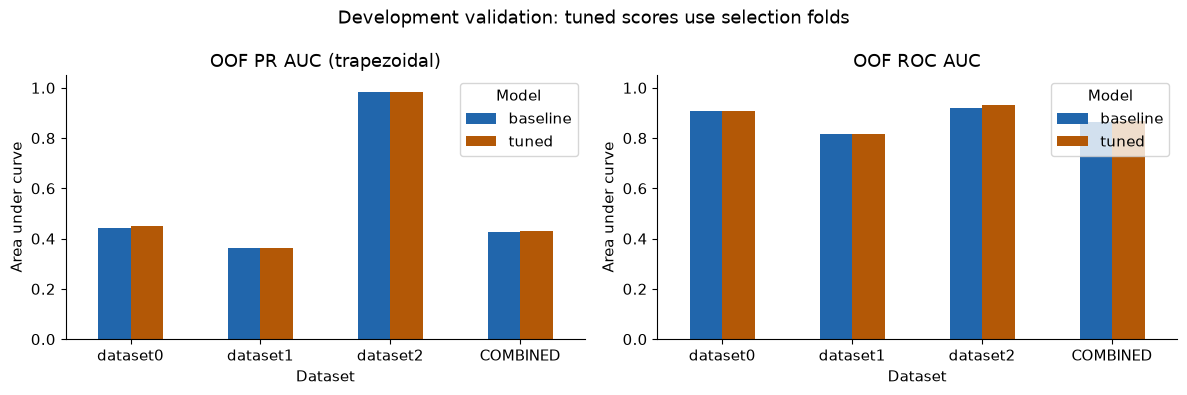

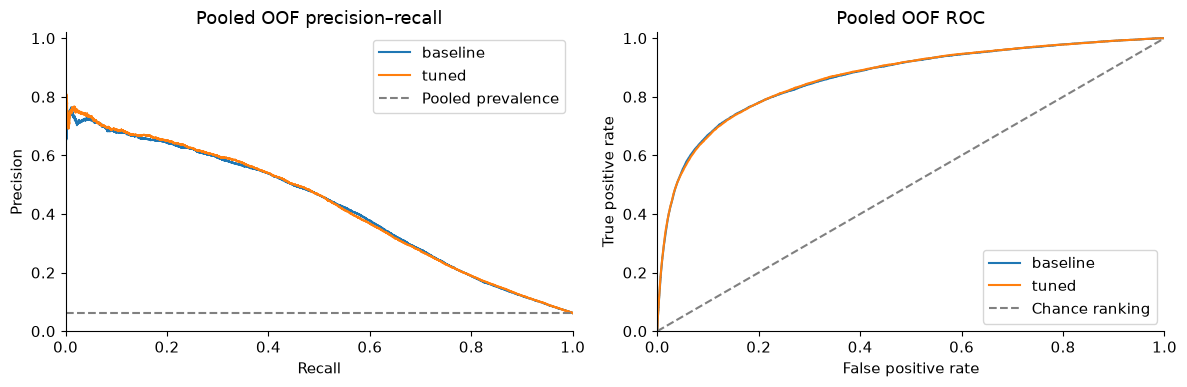

In [10]:
oof_results = results.loc[results.evaluation.eq('oof_validation')]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes, ['pr_auc','roc_auc'], ['OOF PR AUC (trapezoidal)', 'OOF ROC AUC']):
    table = oof_results.pivot(index='dataset', columns='model', values=metric).reindex(ids + ['COMBINED'])
    table.plot.bar(ax=ax, rot=0, color=['#2166ac','#b35806'][:len(table.columns)])
    ax.set(title=title, xlabel='Dataset', ylabel='Area under curve', ylim=(0,1.05))
    ax.legend(title='Model')
fig.suptitle('Development validation: tuned scores use selection folds')
fig.tight_layout(); fig.savefig(RUN_DIR / 'auc_comparison.png', dpi=160, bbox_inches='tight'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, bundle in model_outputs.items():
    scores = bundle[3]
    precision, recall, _ = precision_recall_curve(y, scores)
    fpr, tpr, _ = roc_curve(y, scores)
    axes[0].plot(recall, precision, label=name)
    axes[1].plot(fpr, tpr, label=name)
axes[0].axhline(y.mean(), ls='--', color='gray', label='Pooled prevalence')
axes[1].plot([0,1],[0,1], '--', color='gray', label='Chance ranking')
axes[0].set(title='Pooled OOF precision–recall', xlabel='Recall', ylabel='Precision', xlim=(0,1), ylim=(0,1.02))
axes[1].set(title='Pooled OOF ROC', xlabel='False positive rate', ylabel='True positive rate', xlim=(0,1), ylim=(0,1.02))
for ax in axes: ax.legend()
fig.tight_layout(); fig.savefig(RUN_DIR / 'pooled_oof_curves.png', dpi=160); plt.show()

## 11. Export one prediction CSV per input dataset
The **selected full-data model** produces `predictions/selected/dataset0_predictions.csv`, `dataset1_predictions.csv`, etc. Baseline and tuned predictions are also saved in their own folders for comparison. These files have exactly the handout's three columns:

`transcript_id,transcript_position,score`

`score` is the sigmoid output in [0,1], not a 0/1 decision. No dataset ID, true label, fraction or pandas index is added. The cleaner preserves original transcript IDs and integer positions; no coordinate shift is performed here.

Default prediction inputs contain **all QC-passing signal sites**. Sites discarded by cleaning are absent: these CSVs have the requested format but are not guaranteed complete raw-JSON submissions. Check quarantined-site handling and raw key coverage before submitting. Evaluation uses the binary-labelled subset only. Unlabelled signal rows cannot be used for supervised training or evaluation.

Predictions from CV and the final full-data model differ: the CSVs in `selected/` use the single final full-data model. Labelled-site OOF scores are separately saved under `oof/` for audit.

In [11]:
export_rows = []
for entry in resolved_inputs:
    name = entry['dataset_id']
    pred = pd.read_csv(entry['predict_csv'], dtype={'transcript_id': str})
    if 'dataset_id' in pred and not pred.dataset_id.eq(name).all():
        raise ValueError(f'{name}: prediction table has a mismatched dataset_id.')
    pred_X = validate_features(pred)
    # Prove training rows are present and use the same features in the prediction table.
    training_rows = df.loc[df.dataset_id.eq(name), KEY + FEATURE_COLUMNS]
    matched = training_rows.merge(pred[KEY+FEATURE_COLUMNS], on=KEY, how='left',
                                  suffixes=('_train','_predict'), validate='one_to_one', indicator=True)
    if not matched['_merge'].eq('both').all():
        raise ValueError(f'{name}: prediction input is missing labelled training sites.')
    np.testing.assert_allclose(matched[[c+'_train' for c in FEATURE_COLUMNS]],
                               matched[[c+'_predict' for c in FEATURE_COLUMNS]], rtol=1e-6, atol=1e-8)
    selected_scores = None
    for model_name, bundle in model_outputs.items():
        model, scaler = bundle[:2]
        scores = predict_scores(model, scaler, pred_X)
        export_scores(pred, scores, RUN_DIR / 'predictions' / model_name / f'{name}_predictions.csv')
        mask = df.dataset_id.eq(name).to_numpy()
        export_scores(df.loc[mask], bundle[3][mask], RUN_DIR / 'oof' / model_name / f'{name}_oof.csv')
        if model_name == winner: selected_scores = scores
    path = RUN_DIR / 'predictions' / 'selected' / f'{name}_predictions.csv'
    export_scores(pred, selected_scores, path)
    export_rows.append(dict(dataset_id=name, prediction_rows=len(pred),
                           evaluated_rows=int(df.dataset_id.eq(name).sum()), selected_csv=str(path.resolve())))
    del pred_X, matched
export_manifest = pd.DataFrame(export_rows)
export_manifest.to_csv(RUN_DIR / 'prediction_files.csv', index=False)
display(export_manifest)

,dataset_id,prediction_rows,evaluated_rows,selected_csv
0,dataset0,121838,121838,D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_ge...
1,dataset1,90810,90810,D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_ge...
2,dataset2,1323,1323,D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_ge...


## 12. Reload the selected model and predict a cleaned table
The helper below requires the same 45 feature columns and site keys, but no labels or gene IDs. It performs inference only and applies the saved scaler. Only load model/scaler files you trust. Keep the `.pt`, `_scaler.joblib` and `_metadata.json` files together.

In [12]:
def load_and_predict_cleaned(cleaned_csv, model_dir, name='selected'):
    model_dir = Path(model_dir)
    meta = json.loads((model_dir / f'{name}_metadata.json').read_text())
    if meta['feature_columns'] != FEATURE_COLUMNS or meta['input_size'] != INPUT_SIZE:
        raise ValueError('Saved model feature schema differs from this notebook.')
    config = meta['config']
    model = SiteLSTM(int(config['hidden_size']), float(config['dropout'])).to(DEVICE)
    state = torch.load(model_dir / f'{name}.pt', map_location=DEVICE, weights_only=True)
    model.load_state_dict(state)
    scaler = joblib.load(model_dir / f'{name}_scaler.joblib')
    frame = pd.read_csv(cleaned_csv, dtype={'transcript_id': str})
    scores = predict_scores(model, scaler, validate_features(frame))
    result = frame[KEY].copy()
    result['score'] = scores
    return result


# Verify saved weights/scaler reproduce predictions on the first labelled file.
reloaded = load_and_predict_cleaned(resolved_inputs[0]['train_csv'], RUN_DIR, 'selected')
mask = df.dataset_id.eq(ids[0]).to_numpy()
np.testing.assert_allclose(reloaded.score, model_outputs[winner][2][mask], rtol=1e-5, atol=1e-6)
print('Saved-model reload check passed.')

# To predict a future cleaned file:
# new_predictions = load_and_predict_cleaned('/absolute/path/clean_signal_sites.csv.gz', RUN_DIR)
# new_predictions.to_csv('/absolute/path/predictions.csv', index=False)

Saved-model reload check passed.


## 13. Save reproducibility information and understand the outputs
`all_evaluation_results.csv` contains every dataset plus COMBINED, baseline/tuned, training/OOF metrics. `baseline_vs_tuned_changes.csv` records AUC changes. `selected_model.json` records the winner and selection rule. `prediction_files.csv` lists the final per-dataset CSV paths. Model files include preprocessing metadata.

The manifest records input hashes, cleaning manifests (including dataset2's fraction rule), package versions, settings and model choice. Hashing large cleaned files may take a little time. Fixed seeds improve repeatability but do not guarantee identical results across different hardware or PyTorch versions.

In [13]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024*1024), b''): digest.update(block)
    return digest.hexdigest()

input_records = []
for entry in resolved_inputs:
    record = entry.copy()
    record['train_sha256'] = sha256_file(entry['train_csv'])
    record['predict_sha256'] = sha256_file(entry['predict_csv'])
    input_records.append(record)
versions = {p: importlib.metadata.version(p) for p in ['torch','numpy','pandas','scikit-learn','matplotlib','joblib']}
manifest = dict(inputs=input_records, cleaning_manifests=manifests, feature_columns=FEATURE_COLUMNS,
    label='Binary label only; modification_fraction ignored', sites=len(y), positive_sites=int(y.sum()),
    seed=SEED, folds=N_FOLDS, run_tuning=RUN_TUNING, tuning_trials=N_TRIALS if RUN_TUNING else 0,
    baseline=BASELINE, search_space=SEARCH_SPACE, selected_config=selected_config, selected_model=winner,
    versions=versions, python=sys.version, platform=platform.platform(), device=str(DEVICE),
    evaluation='Training resubstitution plus grouped OOF development validation; tuning/selection folds reused.')
(RUN_DIR / 'run_manifest.json').write_text(json.dumps(manifest, indent=2))
print('Completed. Results:', RUN_DIR.resolve())
print('Final CSVs:', (RUN_DIR / 'predictions' / 'selected').resolve())

Completed. Results: D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\outputs\lstm_output\20261007T031749_054814Z
Final CSVs: D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\outputs\lstm_output\20261007T031749_054814Z\predictions\selected


## Checks and next steps
- Verify dataset0/1/2 are all present in the input summary, with sensible binary class counts. The cleaner must enable all three and apply your chosen dataset2 fraction conversion. This notebook never invents a conversion threshold.
- A `single class` status means that dataset cannot support its own ROC/PR AUC; it is still included in pooled training and predictions. Pooled AUC may conceal dataset differences, so inspect the individual rows.
- Compare changes for each dataset as well as COMBINED. A selected winner can improve pooled PR AUC while lowering ROC AUC or weakening one dataset; the selection policy intentionally gives PR AUC priority.
- A good training score is not evidence of generalization. Tuning-fold scores are also optimistic after selection. The project handout requires independent evaluation; add untouched test data or nested CV for the final report, plus the simple-model and m6Anet benchmarks.
- This is a modelling notebook that consumes cleaned CSVs. The final handout also requires separate training and prediction scripts accepting the specified raw JSON, complete site coverage, repository documentation and small prediction test data.
- Record AI assistance and any verified errors/fixes as required by the project.

**Sources:** supplied `m6a_clean_multiple_datasets.ipynb` (45 summary features; binary `label`; separate exports; optional genes; fraction conversion) and `handout_project2_RNAModifications.html` (three-column probability output and assessment).
Implementation references: [PyTorch LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html), [BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html), [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html).

**Local full-data validation:** set input paths and use **Restart Kernel → Run All**. Inspect the input summary, fold table, evaluation tables, plots and reload check. The delivered notebook deliberately contains no synthetic or fabricated performance outputs.

**Implementation verification completed:** executed every code cell on three small synthetic datasets with five folds, two tuning trials and one epoch per fit. Checked missing gene IDs, cross-dataset transcript grouping, a single-class dataset, pooled AUC recomputation, extra unlabelled signal predictions, exact three-column per-dataset CSVs and saved-model reload. Full-size runtime and real-data performance are not verified.